#Fractional-Diffusing Image Processing(Part 2)

Images contain more than pixels — they contain boundaries, shapes, and structures that help us recognise objects. In this experiment, we move beyond mathematical examples and apply our time-fractional PDE model to real images. By observing how the image evolves under different fractional orders and reaction coefficients, we investigate whether the method can separate foreground from background while preserving important edges and details.

**Our goal:** To see what lies behind the pixels and discover how fractional mathematics can transform an image into a meaningful binary representation.

The code was adopted from Part 1 and remains unchanged to ensure consistency and support the reliability and validation of the results. The same parameters and initialisation settings were retained to maintain consistency across the experiments and allow for a fair comparison.(This will be used in the discussion section fellows)

In [40]:

import io
import time
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from math import gamma
from PIL import Image, ImageOps


def normalize(img):
    img = img.astype(float)
    return (img - img.min()) / (img.max() - img.min() + 1e-12)


def laplacian_neumann(u, h=1.0):
    u = np.pad(u, 1, mode="edge")
    return (
        u[:-2, 1:-1] + u[2:, 1:-1]
        + u[1:-1, :-2] + u[1:-1, 2:]
        - 4 * u[1:-1, 1:-1]
    ) / h**2


def f(u, a=0.5, c_s=50.0):
    return c_s * u * (1 - u) * (u - a)


def dt_from_lambda(alpha, lam):
    return (lam / gamma(2 - alpha)) ** (1 / alpha)


def solve(u0, alpha, dt, n_steps, h=1.0,
          a=0.5, c_d=1.0, c_s=50.0, window=None):

    c = dt**(-alpha) / gamma(2 - alpha)
    k = np.arange(n_steps + 1)
    b = (k + 1)**(1 - alpha) - k**(1 - alpha)

    u = u0.copy()
    diffs = []
    trajectory = [u.copy()]

    for n in range(n_steps):
        rhs = c_d * laplacian_neumann(u, h) + f(u, a, c_s)
        history = diffs if window is None else diffs[-window:]

        memory = np.zeros_like(u)
        for j in range(1, len(history) + 1):
            memory += b[j] * history[-j]

        u_new = u - memory + rhs / c
        diffs.append(u_new - u)
        u = u_new
        trajectory.append(u.copy())

    return trajectory


def l1_error(u, gt, thresh=0.5):
    binary = (u > thresh).astype(float)
    return 100 * np.mean(np.abs(binary - gt))


def upload_image():
    from google.colab import files

    uploaded = files.upload()
    if not uploaded:
        return None, None

    name, data = next(iter(uploaded.items()))
    return Image.open(io.BytesIO(data)), name


def to_gray(img, max_side=96):
    img = ImageOps.exif_transpose(img)

    if img.mode in ("RGBA", "LA", "P"):
        img = img.convert("RGBA")
        background = Image.new("RGBA", img.size, "white")
        img = Image.alpha_composite(background, img)

    img = img.convert("L")

    if max_side and max(img.size) > max_side:
        scale = max_side / max(img.size)
        size = (
            max(1, round(img.width * scale)),
            max(1, round(img.height * scale))
        )
        img = img.resize(size, Image.Resampling.LANCZOS)

    return img


def otsu_threshold(x):
    hist, _ = np.histogram(x, bins=256, range=(0, 1))
    p = hist / hist.sum()
    omega = np.cumsum(p)
    mu = np.cumsum(p * np.arange(256))
    variance = (mu[-1] * omega - mu)**2 / (
        omega * (1 - omega) + 1e-12
    )
    return (np.argmax(variance) + 1) / 256


#Upload a picture

Saving Noisy_picture TW kambule.jpg to Noisy_picture TW kambule (3).jpg
Image: Noisy_picture TW kambule (3).jpg
Original size: (842, 1264)
Processing size: (171, 256) (width x height)
Otsu threshold: 0.555
Value of a: 0.500
Foreground classified as ink: 28.91%
Background classified as white: 71.09%


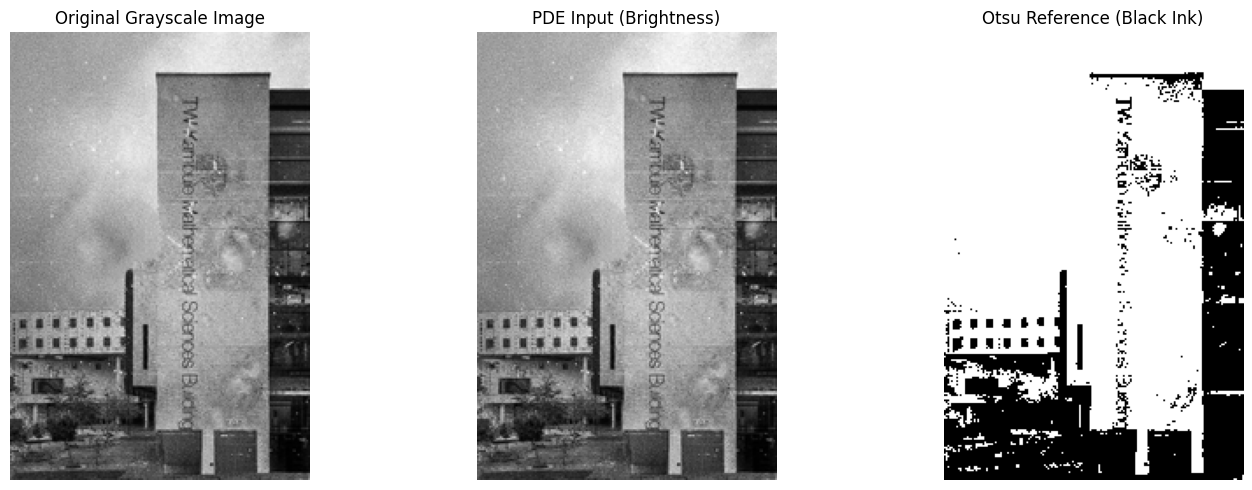

In [38]:


# Settings (unchanged from Part 1)
alphas = [1, 0.8, 0.75, 0.6, 0.5, 0.25]
cs_values = [1, 25, 50]
LAM = 0.05
N_STEPS = 200
C_D = 1.0

MAX_SIDE = 256
INK_IS_DARK = True
A_MODE = "fixed"
ADD_NOISE = False
NOISE_STD = 0.15
MEMORY_WINDOW = None
SNAP_FRACS = [0.05, 0.25, 1.0]

# Upload the original image
pil, fname = upload_image()

if pil is None:
    raise ValueError("No image uploaded. Run this cell again.")

# Convert to grayscale and resize
gray_img = to_gray(pil, MAX_SIDE)
gray = np.asarray(gray_img, dtype=float) / 255.0

print("Image:", fname)
print("Original size:", pil.size)
print("Processing size:", gray_img.size, "(width x height)")

# Prepare the image for PDE processing
ink = 1 - gray if INK_IS_DARK else gray

if ink.max() - ink.min() < 1e-6:
    raise ValueError("The image has no contrast.")

u0_clean = normalize(ink)

rng = np.random.default_rng(0)
u0 = (
    normalize(u0_clean + NOISE_STD * rng.standard_normal(u0_clean.shape))
    if ADD_NOISE else u0_clean.copy()
)

# Calculate Otsu threshold
t_otsu = otsu_threshold(u0_clean)

# Otsu reference: 1 = foreground ink, 0 = background
otsu_ref = (u0_clean > t_otsu).astype(float)

# Keep the original reaction parameter setting
a_val = t_otsu if A_MODE == "otsu" else 0.5
gt = None

print(f"Otsu threshold: {t_otsu:.3f}")
print(f"Value of a: {a_val:.3f}")
print(f"Foreground classified as ink: {100 * otsu_ref.mean():.2f}%")
print(f"Background classified as white: {100 * (1 - otsu_ref.mean()):.2f}%")

# Display the original and prepared images
fig, ax = plt.subplots(1, 3, figsize=(15, 5))

ax[0].imshow(gray, cmap="gray", vmin=0, vmax=1)
ax[0].set_title("Original Grayscale Image")

ax[1].imshow(1 - u0_clean, cmap="gray", vmin=0, vmax=1)
ax[1].set_title("PDE Input (Brightness)")

# Invert only for display: foreground ink should look black
ax[2].imshow(1 - otsu_ref, cmap="gray", vmin=0, vmax=1)
ax[2].set_title("Otsu Reference (Black Ink)")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()


In [37]:

gt_pil, gt_name = upload_image()

if gt_pil is not None:
    gt_gray = np.asarray(
        to_gray(gt_pil).resize(u0.shape[::-1], Image.Resampling.NEAREST)
    ) / 255.0

    gt = (
        (1 - gt_gray) > 0.5 if INK_IS_DARK
        else gt_gray > 0.5
    ).astype(float)

    print("Ground truth loaded:", gt_name)
else:
    print("No ground truth uploaded. Using the Otsu reference.")


Saving TW_Kambule_Building.jpg to TW_Kambule_Building (8).jpg
Ground truth loaded: TW_Kambule_Building (8).jpg


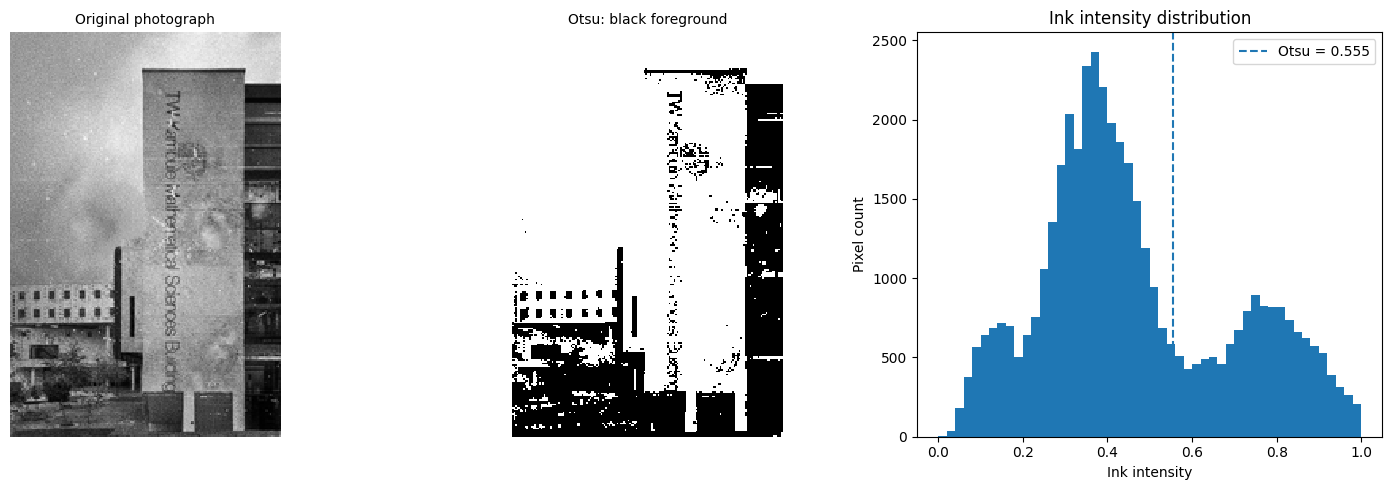

A_MODE: fixed
a_val: 0.5
Otsu threshold: 0.5546875


In [41]:
# Inspect the image intensity distribution
fig, ax = plt.subplots(1, 3, figsize=(15, 5))

show(ax[0], gray, "Original photograph", cmap="gray")
show(ax[1], 1 - otsu_ref, "Otsu: black foreground", cmap="gray")

ax[2].hist(u0_clean.ravel(), bins=50)
ax[2].axvline(t_otsu, linestyle="--", label=f"Otsu = {t_otsu:.3f}")
ax[2].set_title("Ink intensity distribution")
ax[2].set_xlabel("Ink intensity")
ax[2].set_ylabel("Pixel count")
ax[2].legend()

plt.tight_layout()
plt.show()

print("A_MODE:", A_MODE)
print("a_val:", a_val)
print("Otsu threshold:", t_otsu)

Select BOTH pictures. You can hold Ctrl to select files separately.


Saving Noisy picture of TW_Tambule.jpg to Noisy picture of TW_Tambule (1).jpg
Saving TW_Kambule_Building.jpg to TW_Kambule_Building (9).jpg


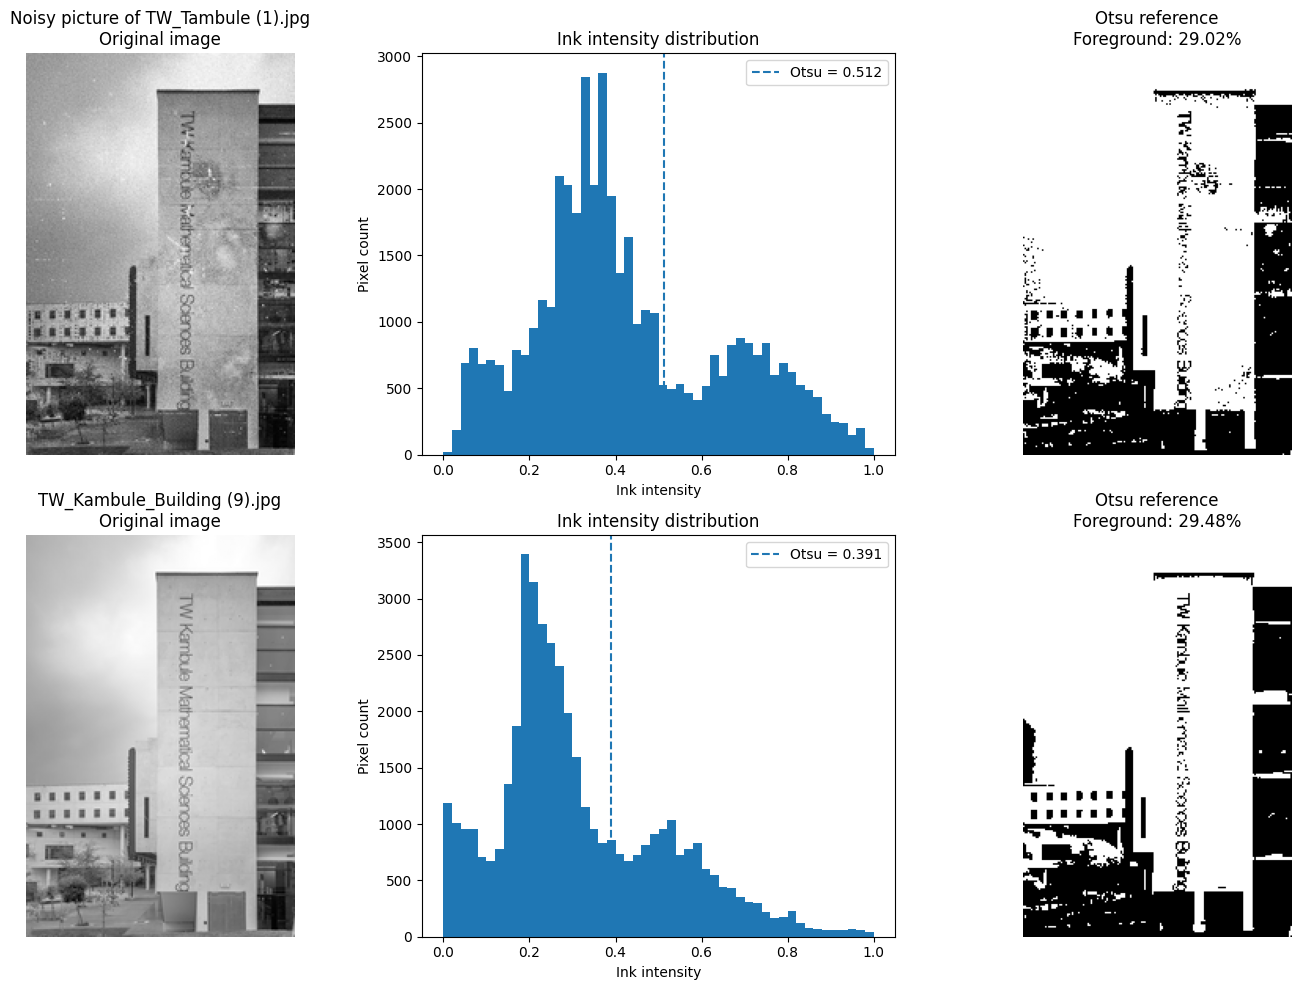

In [43]:

from google.colab import files
from PIL import Image
import io
import numpy as np
import matplotlib.pyplot as plt

# Upload two pictures in one window
print("Select BOTH pictures. You can hold Ctrl to select files separately.")
uploaded = files.upload()

if len(uploaded) != 2:
    raise ValueError(
        f"Please upload exactly 2 pictures. You uploaded {len(uploaded)}."
    )

# Process both pictures
images = {}

for name, data in uploaded.items():
    pil_img = Image.open(io.BytesIO(data))

    # Convert to grayscale and resize consistently
    gray_img = to_gray(pil_img, MAX_SIDE)
    brightness = np.asarray(gray_img, dtype=float) / 255.0

    # Convert to ink intensity
    ink_img = normalize(1 - brightness)

    # Calculate Otsu reference
    threshold = otsu_threshold(ink_img)
    otsu_ref = (ink_img > threshold).astype(float)

    images[name] = {
        "brightness": brightness,
        "ink": ink_img,
        "threshold": threshold,
        "reference": otsu_ref
    }

# Display both pictures side by side
fig, ax = plt.subplots(2, 3, figsize=(15, 10))

for row, (name, result) in enumerate(images.items()):
    ax[row, 0].imshow(
        result["brightness"], cmap="gray", vmin=0, vmax=1
    )
    ax[row, 0].set_title(f"{name}\nOriginal image")

    ax[row, 1].hist(result["ink"].ravel(), bins=50)
    ax[row, 1].axvline(
        result["threshold"], linestyle="--",
        label=f'Otsu = {result["threshold"]:.3f}'
    )
    ax[row, 1].set_title("Ink intensity distribution")
    ax[row, 1].set_xlabel("Ink intensity")
    ax[row, 1].set_ylabel("Pixel count")
    ax[row, 1].legend()

    ax[row, 2].imshow(
        1 - result["reference"], cmap="gray", vmin=0, vmax=1
    )
    ax[row, 2].set_title(
        f'Otsu reference\n'
        f'Foreground: {100 * result["reference"].mean():.2f}%'
    )

    ax[row, 0].axis("off")
    ax[row, 2].axis("off")

plt.tight_layout()
plt.show()


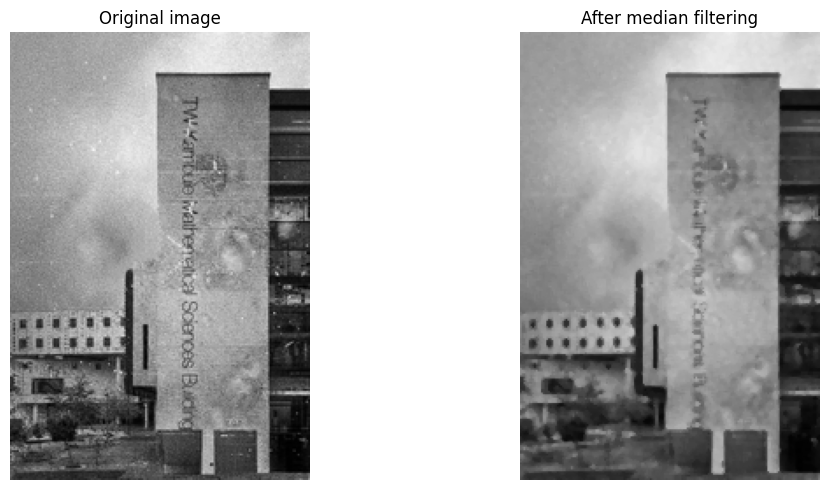

In [44]:
from scipy.ndimage import median_filter

# Apply median filtering to the grayscale image
denoised = median_filter(gray, size=3)

# Compare before and after
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].imshow(gray, cmap="gray", vmin=0, vmax=1)
ax[0].set_title("Original image")

ax[1].imshow(denoised, cmap="gray", vmin=0, vmax=1)
ax[1].set_title("After median filtering")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()

In [45]:

# Run the method for every c_s and alpha

have_gt = gt is not None
reference = gt if have_gt else otsu_ref
err_name = "L1 error vs ground truth" if have_gt else "L1 difference vs Otsu"

snap_steps = sorted({int(round(fr * N_STEPS)) for fr in SNAP_FRACS})

def run_case(alpha, cs):
    dt = dt_from_lambda(alpha, LAM)

    traj = solve(
        u0, alpha, dt, N_STEPS,
        a=a_val, c_d=C_D, c_s=cs,
        window=MEMORY_WINDOW
    )

    binary = [u > 0.5 for u in traj]

    out = {
        "flips": np.array([
            np.nan
        ] + [
            100 * np.mean(binary[n] != binary[n - 1])
            for n in range(1, len(binary))
        ]),
        "undecided": np.array([
            100 * np.mean((u > 0.1) & (u < 0.9))
            for u in traj
        ]),
        "diff": np.array([
            l1_error(u, reference) for u in traj
        ]),
        "snaps": {s: binary[s] for s in snap_steps},
        "final_binary": binary[-1],
        "final_u": traj[-1].copy(),
        "stable": bool(np.isfinite(traj[-1]).all())
    }

    if have_gt:
        out["best_step"] = int(np.argmin(out["diff"]))
        out["best_img"] = binary[out["best_step"]]

    return out


runs = {}
start = time.time()

for cs in cs_values:
    for alpha in alphas:
        result = run_case(alpha, cs)
        runs[(cs, alpha)] = result

        message = (
            f"c_s={cs:>3}, alpha={alpha:<4}  "
            f"final {err_name}={result['diff'][-1]:6.2f}%"
        )

        if have_gt:
            message += (
                f"  best={result['diff'].min():.2f}% "
                f"(step {result['best_step']})"
            )

        if not result["stable"]:
            message += "  <-- unstable (NaN): try a smaller LAM"

        print(message)

print(f"Finished in {time.time() - start:.0f} s")


c_s=  1, alpha=1     final L1 difference vs Otsu= 10.64%
c_s=  1, alpha=0.8   final L1 difference vs Otsu=  9.73%
c_s=  1, alpha=0.75  final L1 difference vs Otsu=  9.24%
c_s=  1, alpha=0.6   final L1 difference vs Otsu=  7.73%
c_s=  1, alpha=0.5   final L1 difference vs Otsu=  7.31%
c_s=  1, alpha=0.25  final L1 difference vs Otsu=  7.20%
c_s= 25, alpha=1     final L1 difference vs Otsu=  7.08%
c_s= 25, alpha=0.8   final L1 difference vs Otsu=  7.01%
c_s= 25, alpha=0.75  final L1 difference vs Otsu=  6.99%
c_s= 25, alpha=0.6   final L1 difference vs Otsu=  6.96%
c_s= 25, alpha=0.5   final L1 difference vs Otsu=  6.93%
c_s= 25, alpha=0.25  final L1 difference vs Otsu=  6.89%
c_s= 50, alpha=1     final L1 difference vs Otsu=  7.05%
c_s= 50, alpha=0.8   final L1 difference vs Otsu=  7.04%
c_s= 50, alpha=0.75  final L1 difference vs Otsu=  7.04%
c_s= 50, alpha=0.6   final L1 difference vs Otsu=  7.02%
c_s= 50, alpha=0.5   final L1 difference vs Otsu=  7.00%
c_s= 50, alpha=0.25  final L1 d

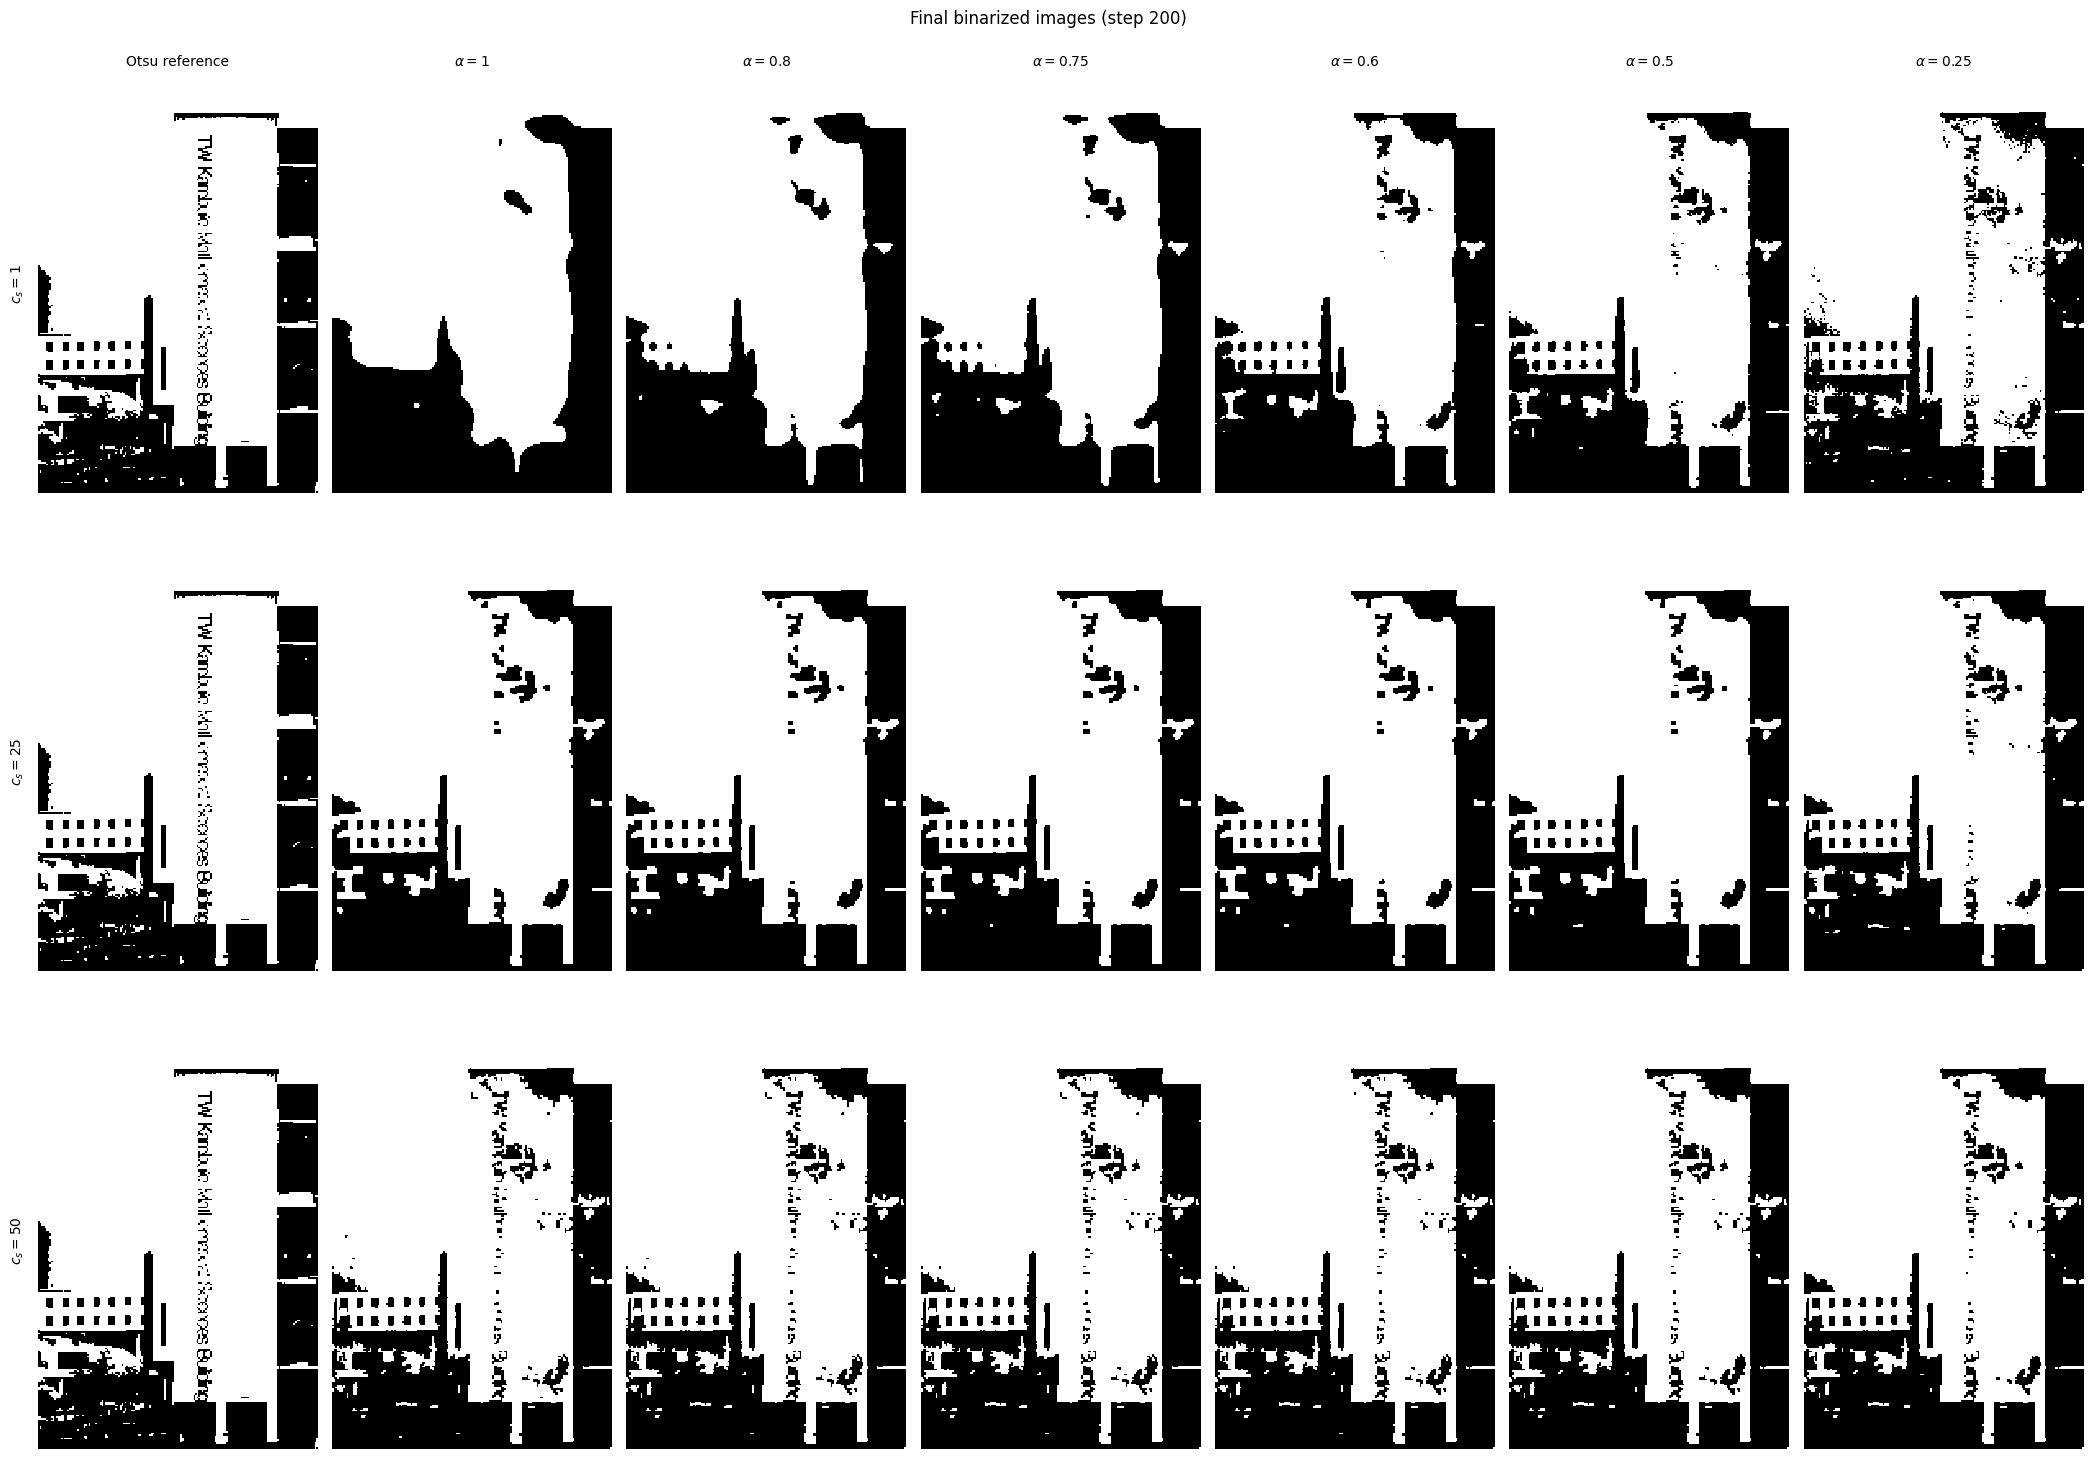

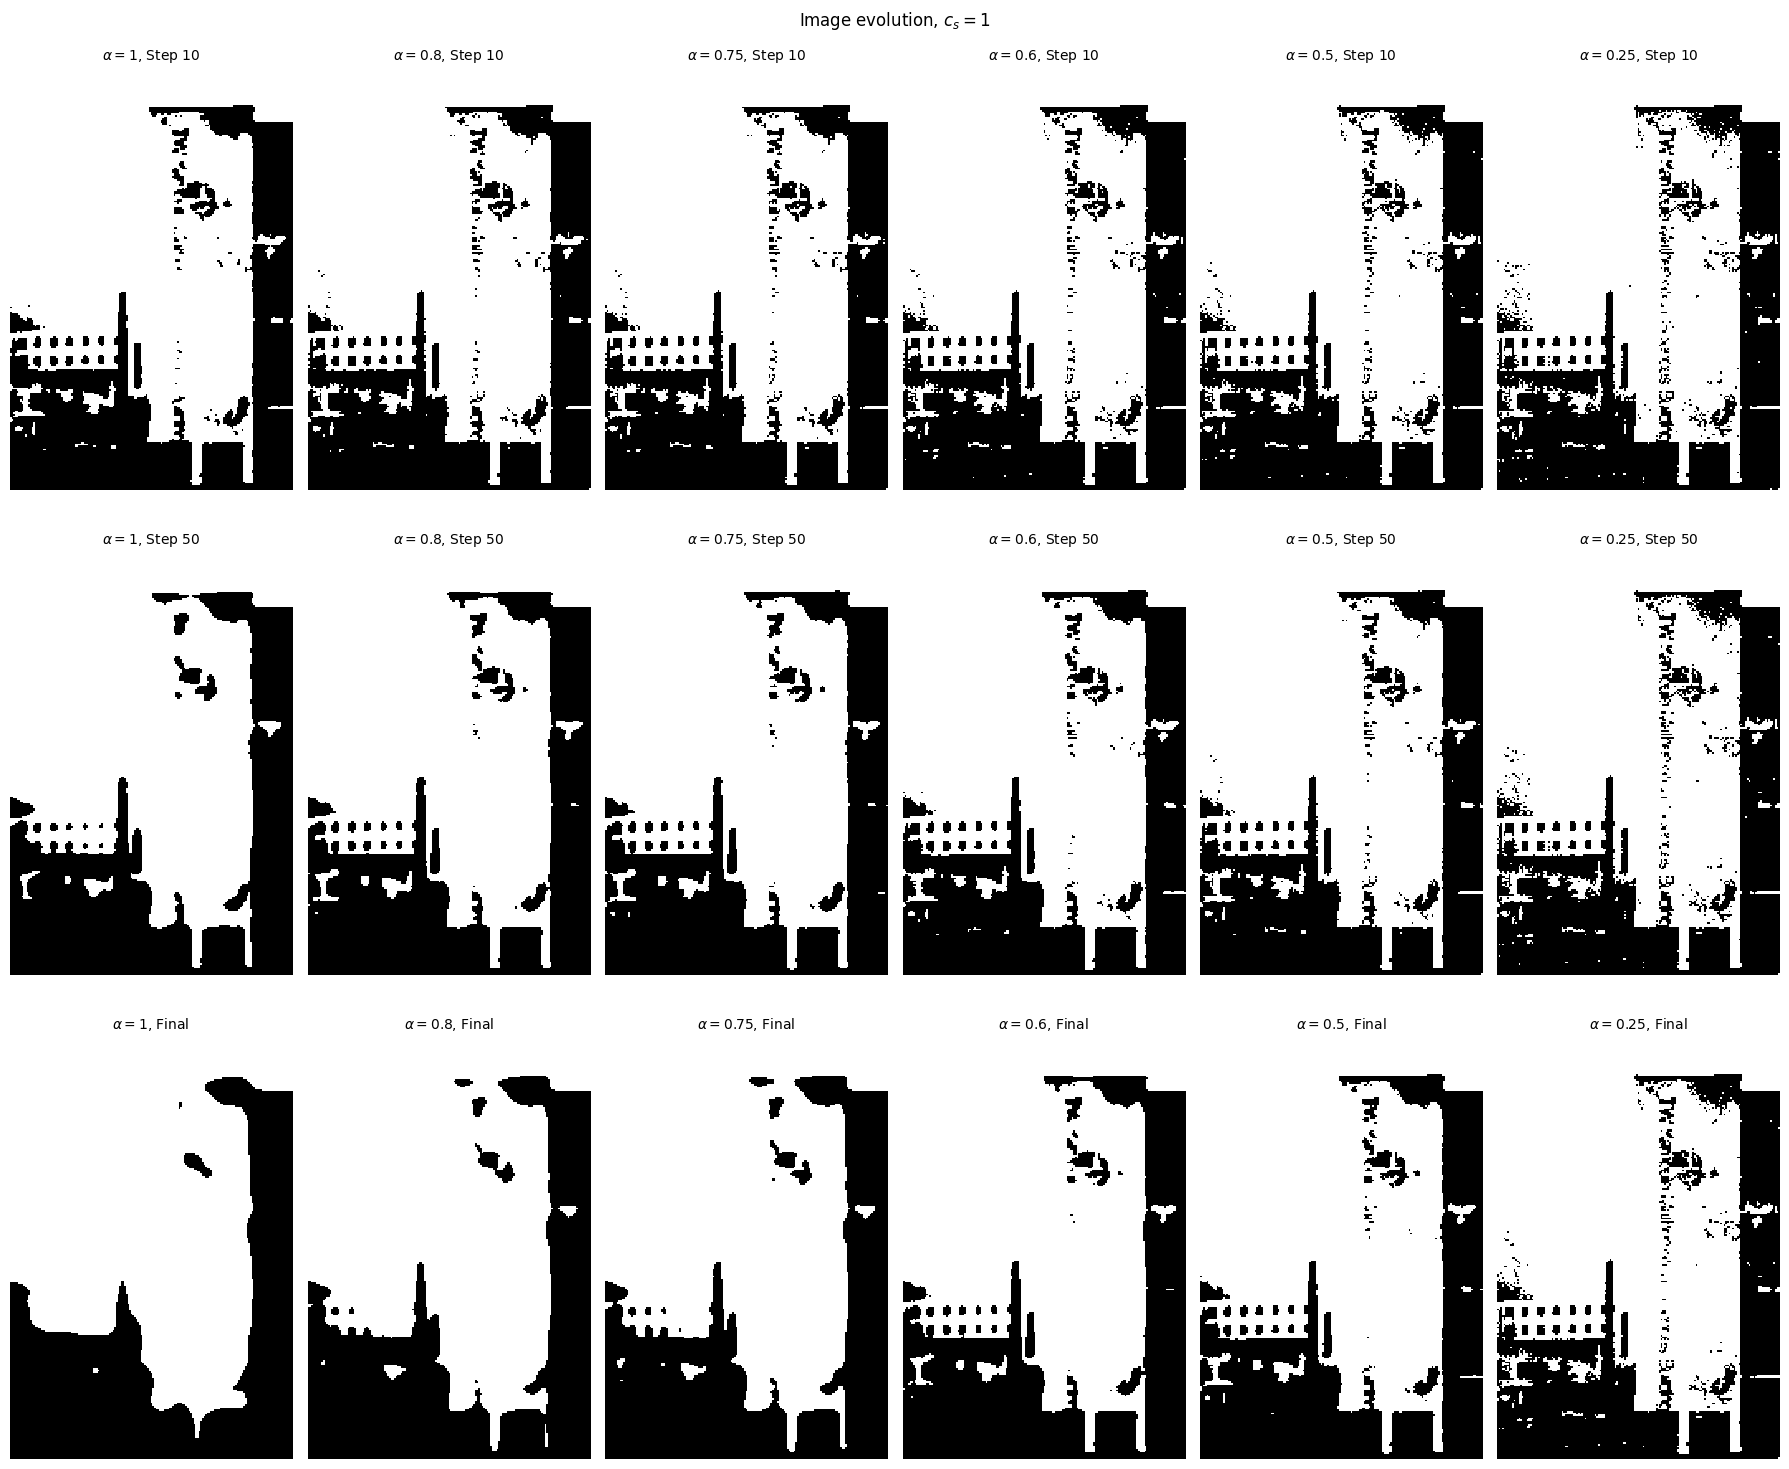

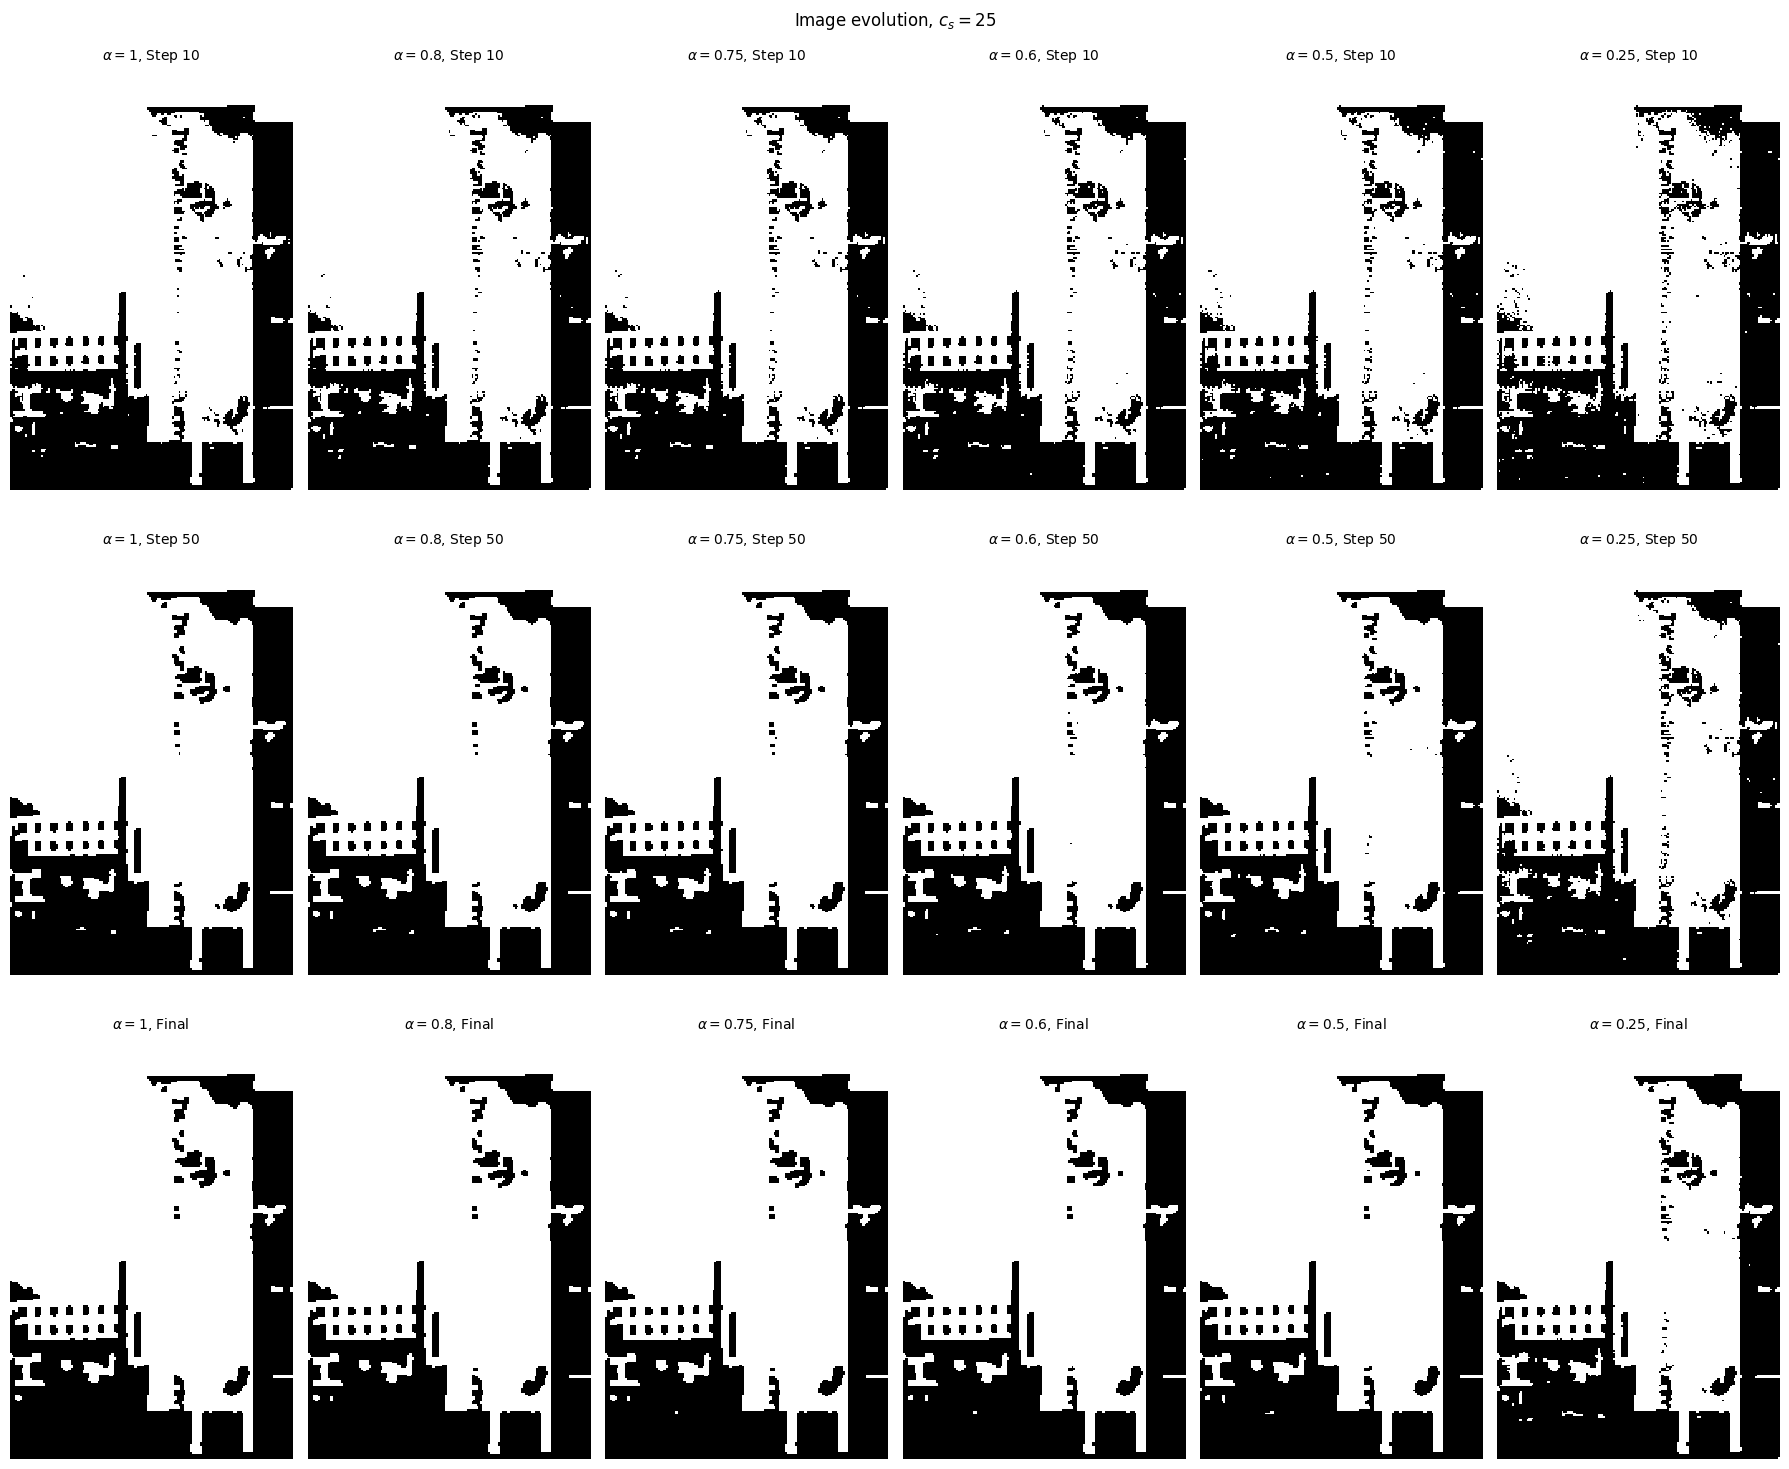

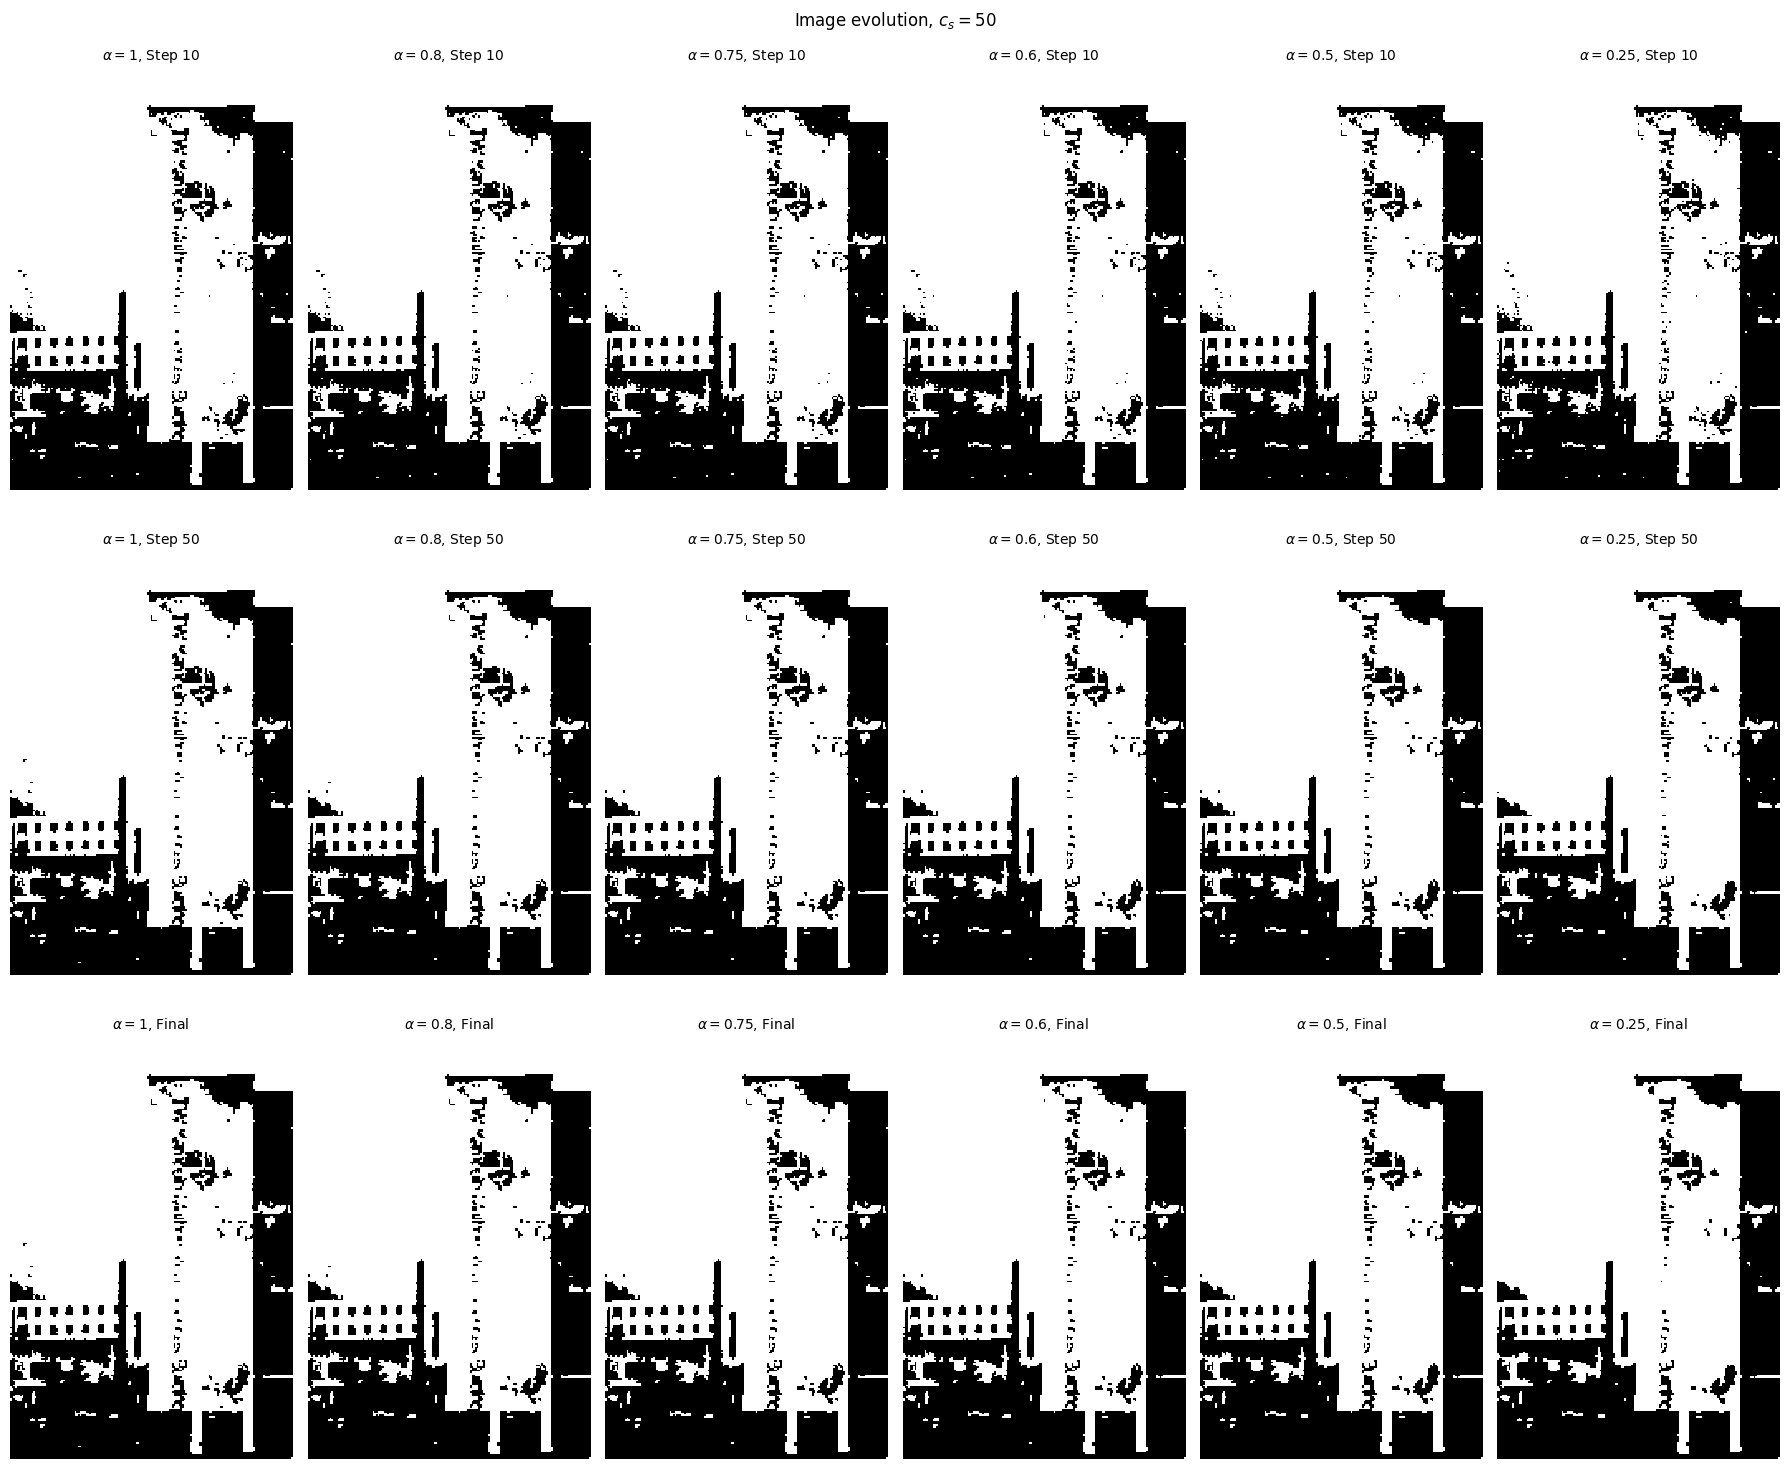

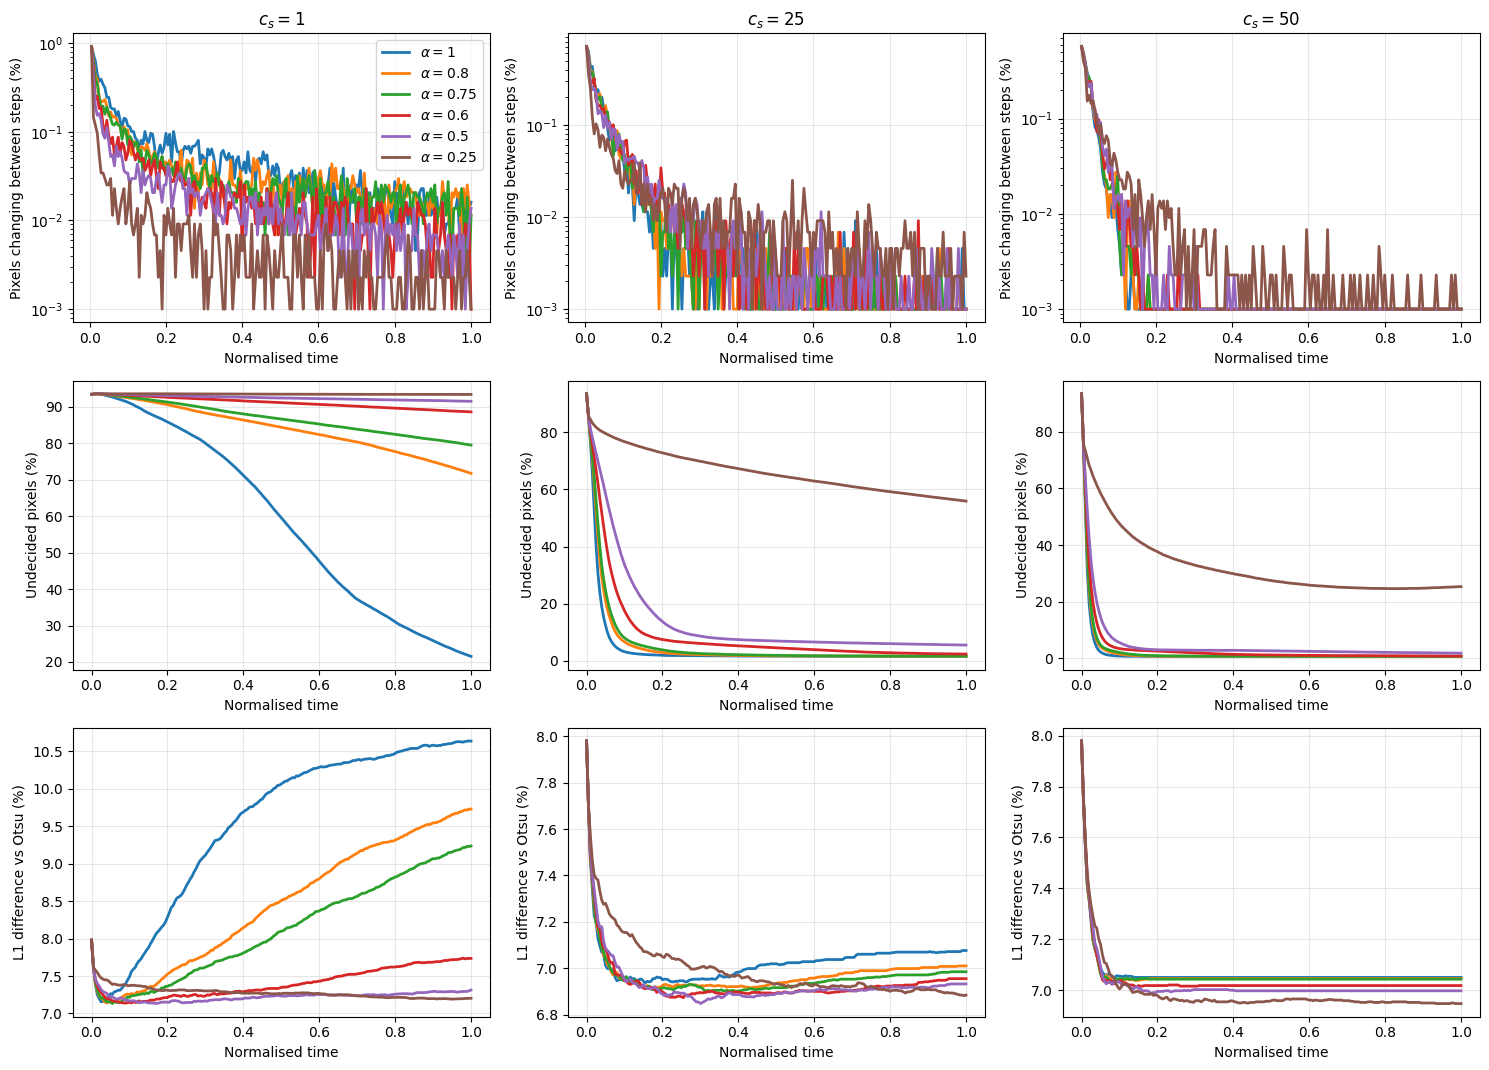

,c_s,alpha,"Undecided pixels, final (%)","Still changing, final (%)","L1 difference vs Otsu, final (%)"
0,1,1.00,21.537,0.016,10.636
1,1,0.80,71.752,0.011,9.729
2,1,0.75,79.518,0.011,9.236
3,1,0.60,88.628,0.000,7.735
4,1,0.50,91.534,0.014,7.312
5,1,0.25,93.416,0.000,7.203
6,25,1.00,1.592,0.000,7.077
7,25,0.80,1.642,0.000,7.011
8,25,0.75,1.658,0.000,6.986
9,25,0.60,2.389,0.000,6.956


Results saved to results_summary.csv


In [47]:

# Results
def show(ax, img, title=None, cmap="gray_r"):
    ax.imshow(
        np.asarray(img, dtype=float),
        cmap=cmap,
        vmin=0,
        vmax=1,
        interpolation="nearest"
    )
    ax.axis("off")

    if title:
        ax.set_title(title, fontsize=10)

H, W = u0.shape

def new_grid(nrows, ncols, cell_w=3.0):
    cell_h = max(cell_w * H / W, 1.2) + 0.35
    return plt.subplots(
        nrows, ncols,
        figsize=(cell_w * ncols, cell_h * nrows + 0.8),
        squeeze=False
    )


# 1. Final processed images
ref_label = "Ground truth" if have_gt else "Otsu reference"
fig, axes = new_grid(len(cs_values), len(alphas) + 1)

for i, cs in enumerate(cs_values):
    show(axes[i, 0], reference, ref_label if i == 0 else None)
    axes[i, 0].text(
        -0.04, 0.5, f"$c_s={cs}$",
        transform=axes[i, 0].transAxes,
        rotation=90, ha="right", va="center"
    )

    for j, alpha in enumerate(alphas):
        show(
            axes[i, j + 1],
            runs[(cs, alpha)]["final_binary"],
            rf"$\alpha={alpha}$" if i == 0 else None
        )

fig.suptitle(f"Final binarized images (step {N_STEPS})")
plt.tight_layout()
plt.show()


# 2. Image evolution over time
for cs in cs_values:
    row_keys = (["best"] if have_gt else []) + snap_steps
    fig, axes = new_grid(len(row_keys), len(alphas))

    for i, step in enumerate(row_keys):
        for j, alpha in enumerate(alphas):
            result = runs[(cs, alpha)]

            if step == "best":
                img = result["best_img"]
                label = f"Best, step {result['best_step']}"
            else:
                img = result["snaps"][step]
                label = "Final" if step == N_STEPS else f"Step {step}"

            show(axes[i, j], img, rf"$\alpha={alpha}$, {label}")

    fig.suptitle(rf"Image evolution, $c_s={cs}$")
    plt.tight_layout()
    plt.show()


# 3. Curves over normalised time
metrics = [
    ("flips", "Pixels changing between steps (%)", True),
    ("undecided", "Undecided pixels (%)", False),
    ("diff", err_name + " (%)", False)
]

fig, axes = plt.subplots(
    len(metrics), len(cs_values),
    figsize=(5 * len(cs_values), 3.6 * len(metrics)),
    squeeze=False
)

for m, (key, ylabel, log_scale) in enumerate(metrics):
    for c, cs in enumerate(cs_values):
        ax = axes[m, c]

        for alpha in alphas:
            values = runs[(cs, alpha)][key]
            t_axis = np.linspace(0, 1, len(values))
            y = np.maximum(values, 1e-3) if log_scale else values

            ax.plot(t_axis, y, linewidth=2, label=rf"$\alpha={alpha}$")

        if log_scale:
            ax.set_yscale("log")

        if m == 0:
            ax.set_title(rf"$c_s={cs}$")

        ax.set_xlabel("Normalised time")
        ax.set_ylabel(ylabel)
        ax.grid(alpha=0.3)

        if m == 0 and c == 0:
            ax.legend()

plt.tight_layout()
plt.show()


# 4. Summary table
rows = []

for (cs, alpha), result in runs.items():
    row = {
        "c_s": cs,
        "alpha": alpha,
        "Undecided pixels, final (%)": result["undecided"][-1],
        "Still changing, final (%)": result["flips"][-1],
        err_name + ", final (%)": result["diff"][-1]
    }

    if have_gt:
        row["Best error (%)"] = result["diff"].min()
        row["Best step"] = result["best_step"]

    rows.append(row)

summary = pd.DataFrame(rows)
display(summary.round(3))
summary.to_csv("results_summary.csv", index=False)

print("Results saved to results_summary.csv")


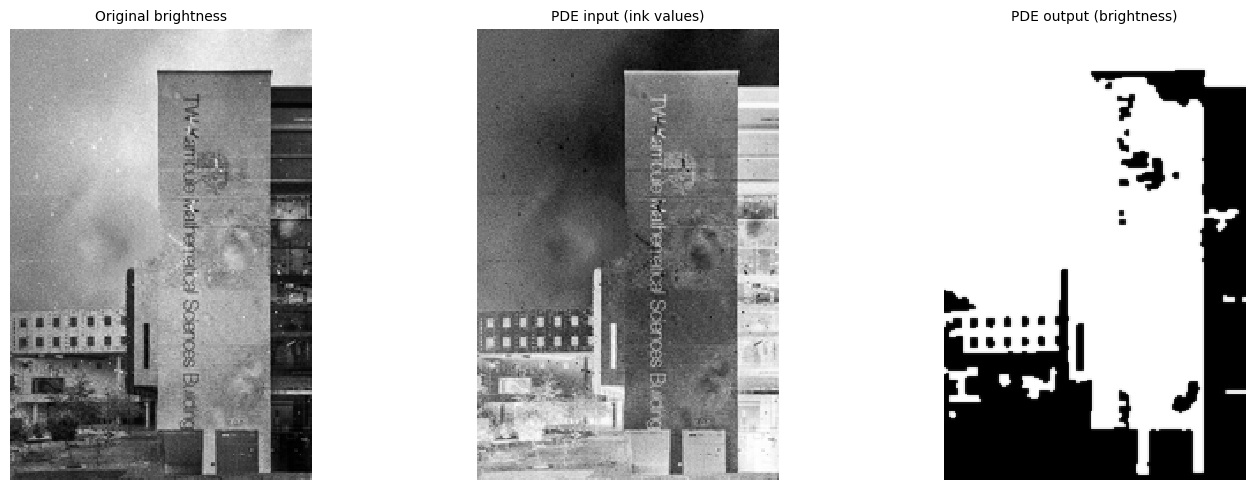

In [48]:


# Compare the PDE output in ink values and original brightness

r = runs[(25, 1)]

fig, ax = plt.subplots(1, 3, figsize=(15, 5))

show(ax[0], gray, "Original brightness", cmap="gray")
show(ax[1], u0, "PDE input (ink values)", cmap="gray")
show(ax[2], 1 - r["final_u"], "PDE output (brightness)", cmap="gray")

plt.tight_layout()
plt.show()


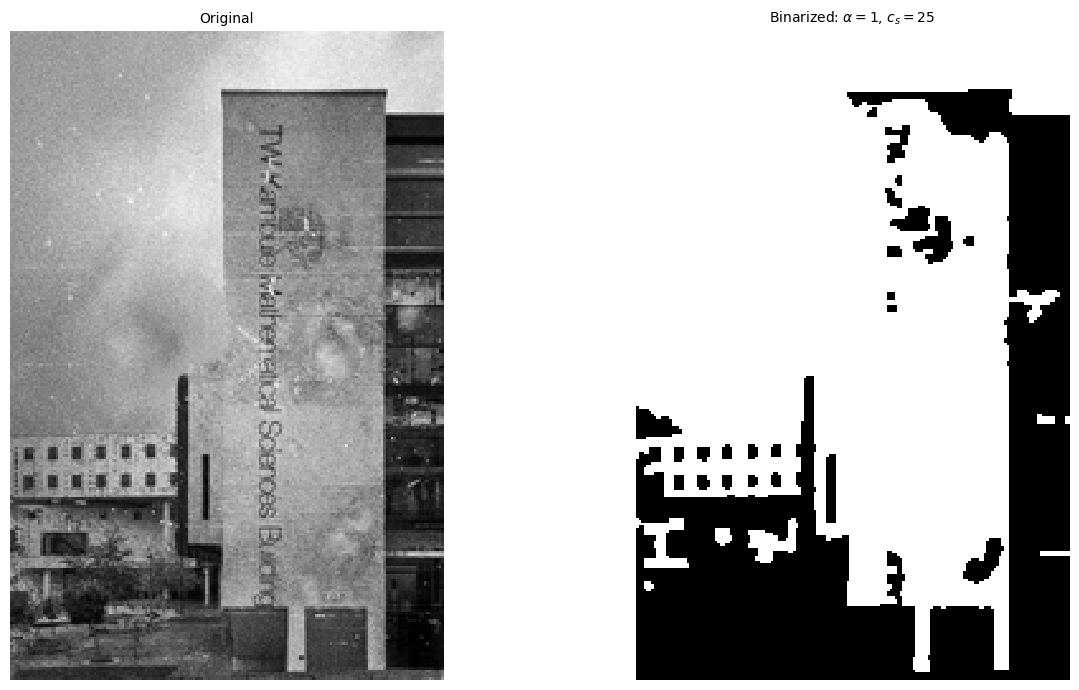

In [49]:
# View the result next to the original image
PICK_ALPHA = 1
PICK_CS = 25

r = runs[(PICK_CS, PICK_ALPHA)]

fig, ax = plt.subplots(1, 2, figsize=(14, 7))

show(ax[0], gray, "Original", cmap="gray")
show(ax[1], r["final_binary"],
     rf"Binarized: $\alpha={PICK_ALPHA}$, $c_s={PICK_CS}$")

plt.tight_layout()
plt.show()

Remove the `#` symbols (uncomment this section) when you want to download the results and please keep the plots as well. I tried adding a few things to see if they would work, but they didn't.

In [ ]:

# Download the binarized images and summary table

#import os
#import shutil
#from google.colab import files

#os.makedirs("results", exist_ok=True)


#for (cs, alpha), result in runs.items():
    #image = np.where(result["final_binary"], 0, 255).astype("uint8")
    #Image.fromarray(image).save(
        #f"results/binary_cs{cs}_alpha{alpha}.png"
    #)

#reference_image = np.where(reference > 0.5, 0, 255).astype("uint8")
#Image.fromarray(reference_image).save("results/reference.png")
#summary.to_csv("results/results_summary.csv", index=False)


#shutil.make_archive("binarization_results", "zip", "results")
#files.download("binarization_results.zip")


### Further Investigation: Image Denoising and Binarization

We continued investigating the validity of our results by uploading a noisy image and examining whether the fractional PDE could clean it effectively. This investigation helped us identify an important distinction between image denoising and image binarization.

The fractional PDE considered in this study combines diffusion with a nonlinear reaction term that encourages pixel values towards two stable states. Although diffusion may smooth local variations, the method does not necessarily remove unwanted marks and may affect fine details. Our experiments therefore demonstrate that successful binarization does not automatically imply successful denoising.

We will continue investigating the validity of these results and consider dedicated denoising methods, such as median filtering, for comparison. This will help us evaluate noise reduction and detail preservation separately and better understand the capabilities and limitations of the fractional PDE.